In [1]:
import torch 
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets,transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

import numpy as np
import pandas as pd
import  matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [ ]:
#transform MNIST dataset(image files) into tensor 4 damensions(image,height,width,color channel)
transform=transforms.ToTensor()

In [3]:
#train data
train_data=datasets.MNIST(root='/cnn_root',train=True,transform=transform,download=True)

100.0%
100.0%
100.0%
100.0%


In [4]:
#test data
test_data=datasets.MNIST(root='/cnn_root',train=False,download=True,transform=transform)

In [5]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: /cnn_root
    Split: Train
    StandardTransform
Transform: ToTensor()

In [6]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: /cnn_root
    Split: Test
    StandardTransform
Transform: ToTensor()

In [ ]:
class ConvolutionalNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        #the input has 1 channel because the image is grayscale. A color image would have 3 (red, green, blue)
        #stride=1:The window moves 1 pixel at a time.
        self.conv1=nn.Conv2d(1,6,3,1)# 1 channel in -> 6 filters, 3x3 kernel, stride 1
        self.conv2=nn.Conv2d(6,16,3,1)# 6 channels in -> 16 filters, 3x3 kernel, stride 1


        #fully connected layers 
        self.fc1=nn.Linear(5*5*16,120)
        self.fc2=nn.Linear(120,84)
        self.fc3=nn.Linear(84,10)# 10 = number of digits (0 to 9)

    def forward(self,X):
        # SIZE TRAIL (height x width), conv: size - 2, pool: size / 2 (rounded down)
        # 1- input        : 28x28   (1 channel)
        # 2- conv1        : 28 - 2 = 26x26   (6 maps)
        # 3- pool         : 26 / 2 = 13x13
        # 4- conv2        : 13 - 2 = 11x11   (16 maps)
        # 5- pool         : 11 / 2 = 5x5     (5.5 rounded down)
        # 6- flatten      : 5 x 5 x 16 = 400 numbers
        # 7- fc1          : 400 -> 120
        # 8- fc2          : 120 -> 84
        # 9- fc3          : 84 -> 10 scores
        #first pass
        X=F.relu(self.conv1(X))# 28x28 -> 26x26
        X=F.max_pool2d(X,2,2)# 26x26 -> 13x13 (kernel 2, stride 2)

        #second pass
        X=F.relu(self.conv2(X)) # 13x13 -> 11x11
        X=F.max_pool2d(X,2,2)# 11x11 -> 5x5

        # flatten: 16 maps x 5 x 5 = 400 (-1 lets the batch size vary)
        X=X.view(-1,5*5*16)

        # Fully Connected Layers
        X=F.relu(self.fc1(X))# 400 -> 120
        X=F.relu(self.fc2(X))# 120 -> 84
        X=self.fc3(X)# 84 -> 10 (no relu on the last layer)
        return X






In [8]:

# Create an Instance of our Model
torch.manual_seed(41)
model=ConvolutionalNetwork()
model

ConvolutionalNetwork(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [13]:
# Loss Function Optimizer
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.001)

In [14]:
# Create a small batch size for images...let's say 10
train_loader = DataLoader(train_data, batch_size=10, shuffle=True)
test_loader = DataLoader(test_data, batch_size=10, shuffle=False)

In [15]:
import time
start_time = time.time()

# Create Variables To Tracks Things
epochs = 5
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For Loop of Epochs
for i in range(epochs):
  trn_corr = 0
  tst_corr = 0


  # Train
  for b,(X_train, y_train) in enumerate(train_loader):
    b+=1 # start our batches at 1
    y_pred = model(X_train) # get predicted values from the training set. Not flattened 2D
    loss = criterion(y_pred, y_train) # how off are we? Compare the predictions to correct answers in y_train

    predicted = torch.max(y_pred.data, 1)[1] # add up the number of correct predictions. Indexed off the first point
    batch_corr = (predicted == y_train).sum() # how many we got correct from this batch. True = 1, False=0, sum those up
    trn_corr += batch_corr # keep track as we go along in training.

    # Update our parameters
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    # Print out some results
    if b%600 == 0:
      print(f'Epoch: {i}  Batch: {b}  Loss: {loss.item()}')

  train_losses.append(loss)
  train_correct.append(trn_corr)


  # Test
  with torch.no_grad(): #No gradient so we don't update our weights and biases with test data
    for b,(X_test, y_test) in enumerate(test_loader):
      y_val = model(X_test)
      predicted = torch.max(y_val.data, 1)[1] # Adding up correct predictions
      tst_corr += (predicted == y_test).sum() # T=1 F=0 and sum away


  loss = criterion(y_val, y_test)
  test_losses.append(loss)
  test_correct.append(tst_corr)



current_time = time.time()
total = current_time - start_time
print(f'Training Took: {total/60} minutes!')

Epoch: 0  Batch: 600  Loss: 0.011880090460181236
Epoch: 0  Batch: 1200  Loss: 0.05675176903605461
Epoch: 0  Batch: 1800  Loss: 0.015117106027901173
Epoch: 0  Batch: 2400  Loss: 0.11992499977350235
Epoch: 0  Batch: 3000  Loss: 0.008289739489555359
Epoch: 0  Batch: 3600  Loss: 0.028311502188444138
Epoch: 0  Batch: 4200  Loss: 0.14462041854858398
Epoch: 0  Batch: 4800  Loss: 0.0053411321714520454
Epoch: 0  Batch: 5400  Loss: 0.01544403750449419
Epoch: 0  Batch: 6000  Loss: 0.0024422635324299335
Epoch: 1  Batch: 600  Loss: 0.010749380104243755
Epoch: 1  Batch: 1200  Loss: 0.0074066100642085075
Epoch: 1  Batch: 1800  Loss: 0.05340532213449478
Epoch: 1  Batch: 2400  Loss: 0.3158627450466156
Epoch: 1  Batch: 3000  Loss: 0.08948637545108795
Epoch: 1  Batch: 3600  Loss: 0.00011424579133745283
Epoch: 1  Batch: 4200  Loss: 0.0006565311923623085
Epoch: 1  Batch: 4800  Loss: 0.00032243895111605525
Epoch: 1  Batch: 5400  Loss: 0.004564214497804642
Epoch: 1  Batch: 6000  Loss: 0.0011959270341321826
E

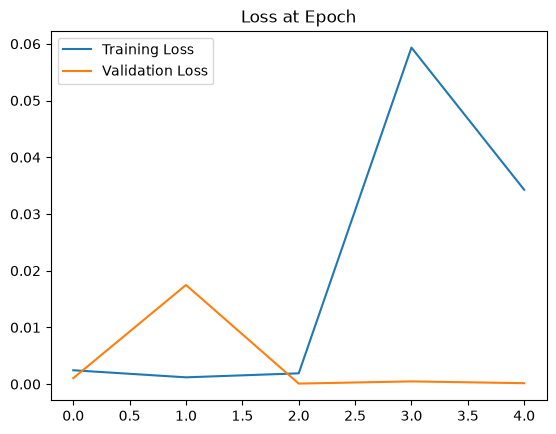

In [16]:
# Graph the loss at epoch
train_losses = [tl.item() for tl in train_losses]
plt.plot(train_losses, label="Training Loss")
plt.plot(test_losses, label="Validation Loss")
plt.title("Loss at Epoch")
plt.legend()

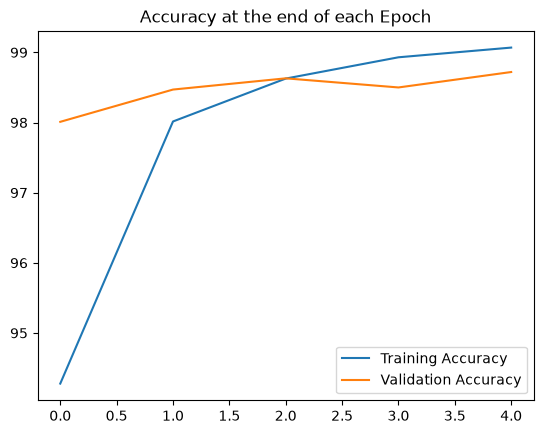

In [17]:

# graph the accuracy at the end of each epoch
plt.plot([t/600 for t in train_correct], label="Training Accuracy")
plt.plot([t/100 for t in test_correct], label="Validation Accuracy")
plt.title("Accuracy at the end of each Epoch")
plt.legend()

In [18]:
test_load_everything = DataLoader(test_data, batch_size=10000, shuffle=False)

In [19]:

with torch.no_grad():
  correct = 0
  for X_test, y_test in test_load_everything:
    y_val = model(X_test)
    predicted = torch.max(y_val, 1)[1]
    correct += (predicted == y_test).sum()
     

In [20]:
# Did for correct
correct.item()/len(test_data)*100

98.72

In [21]:
# Grab an image
test_data[1978] # Tensor with an image in it...at end, it shows the label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [22]:
# Grab just the data
test_data[1978][0]

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [23]:
# Reshape it
test_data[1978][0].reshape(28,28)

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000

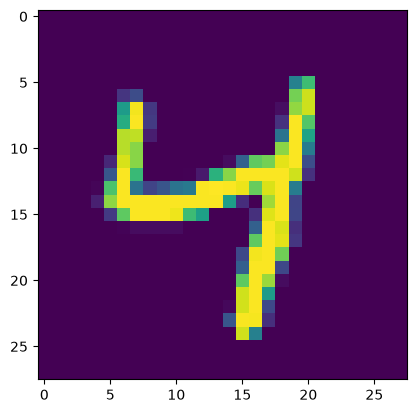

In [24]:
# Show the image
plt.imshow(test_data[1978][0].reshape(28,28))

In [25]:

# Pass the image thru our model
model.eval()
with torch.no_grad():
  new_prediction = model(test_data[1978][0].view(1,1,28,28)) # batch size of 1, 1 color channel, 28x28 image

In [26]:
# Check the new prediction...get probabilities
new_prediction

tensor([[-2.9025e+01, -2.0010e+01, -2.5920e+01, -3.5261e+01, -5.6028e-06,
         -2.2363e+01, -1.9583e+01, -2.0312e+01, -2.2377e+01, -1.2093e+01]])

In [27]:
new_prediction.argmax()

tensor(4)